In [1]:
"""
Callset benchmarking and comparison.
"""

import copy
import importlib
import re
import pickle
import warnings
from pathlib import Path
from collections import defaultdict
import time

import numpy as np
import pandas as pd
import matplotlib as mpl
import pyranges as pr
import pysam
import seaborn as sns
import shap
from scipy.spatial import cKDTree
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import os
from typing import Union, Tuple, Optional, List, Any, Literal, Dict


workdir = "/vast/ai_projects/Papenfuss_SVEnsemble2"
os.chdir(workdir)
os.getcwd()

import svensemble.vcfparse as vcfp # noqa: E402 (flake8)
import svensemble.breakends as bnds
import svensemble.breakpoints as bps
import svensemble.events as evts
import svensemble.caller_specific as caller_specific
import svensemble.benchmark as benchmark
import svensemble._caller_params as caller_params
import svensemble._sample_params as sample_params
import svensemble.chunk_match as chunk_match
import svensemble.matched_breakpoints as matchedbps
import svensemble.utils as sv_utils
import svensemble.importances as importances

importlib.reload(vcfp)
importlib.reload(bnds)
importlib.reload(bps)
importlib.reload(evts)
importlib.reload(caller_specific)
importlib.reload(benchmark)
importlib.reload(caller_params)
importlib.reload(sample_params)
importlib.reload(chunk_match)
importlib.reload(matchedbps)
importlib.reload(sv_utils)

pd.set_option('display.max_columns', None)


In [2]:
# When converting to a py script.
# Input:
# - sample name
# - model name

# - validation set path - ADD LATER

# - sv types - how??? For now use presets.
#   - DEL
#   - ALL
# - sv lengths. Will need 2 separate values for upper and lower bounds.

In [6]:
training_sets =  {
    'gridss': ['gridss'],
    'manta_candidate': ['manta_candidate'],
    'manta_diploid': ['manta_diploid'],
    'gridss+manta_candidate': ['gridss', 'manta_candidate'],
    'gridss+manta_diploid': ['gridss', 'manta_diploid']
}
training_sets = caller_params.training_set_list_presets['default']
callsets = list(set(sum([caller_params.training_set_presets[ts] for ts in training_sets], [])))
callsets+=['gridss_H', 'survivor', 'sniffles', 'sniffles_H']

# sample_names = ['NA12878', 'NA12878_hg19', 'CHM13', 'HG002', 'HG00514']
# sample_names = ['NA12878', 'CHM13', 'HG002', 'HG002_30x']
# sample_names = ['NA12878_30x']
sample_names = ['NA12878_hg19']

val_vcf_paths = {
    # 'kosugi': '/home/users/allstaff/shikov.v/projects/Papenfuss_SVEnsemble2/data/Kosugi_validation/NA12878_DGV-2016_LR-assembly.hg38.bed',
    # 'chm13_val': '/home/users/allstaff/shikov.v/projects/Papenfuss_SVEnsemble2/data/CHM13_validation/supporting_variants_for_nstd137.csv',
    # 'huddleston': '/home/users/allstaff/shikov.v/projects/Papenfuss_SVEnsemble2/data/CHM13_validation/CHM13_SVs.annotated.vcf',
    # 'hg002_val': '/home/users/allstaff/shikov.v/projects/Papenfuss_SVEnsemble2/data/HG002_validation/HG002_validation.vcf.gz',
    # 'hg00514_val': '/home/users/allstaff/shikov.v/projects/Papenfuss_SVEnsemble2/data/HG00514_validation/downloads/supporting_variants_for_nstd152.csv.gz'
}

svtypes_str_default = 'DEL'
svlens_default = (50, np.inf)

verbose = True

# Callsets and svensemble2 calls with names in the blacklist will be excluded from plotting
# training_set_blacklist = ['manta_candidate', 'svensemble2_manta_candidate', 'svensemble2_gridss+manta_candidate+delly', 'svensemble2_gridss+manta_candidate', 'svensemble2_delly+manta_candidate', 'svensemble2_gridss+delly', 'gridss_H']
# training_set_blacklist = ['manta_candidate', 'svensemble2_manta_candidate', 'svensemble2_gridss+manta_candidate+delly', 'svensemble2_gridss+manta_candidate', 'svensemble2_delly+manta_candidate', 'svensemble2_gridss+delly']
training_set_blacklist = ['svensemble2_manta_candidate', 'svensemble2_gridss+manta_candidate+delly', 'svensemble2_gridss+manta_candidate', 'svensemble2_delly+manta_candidate', 'svensemble2_gridss+delly']


In [ ]:
samples = {}
for sample_name in sample_names:
    samples.update(
        sv_utils.create_config_dict(sample_name)
    )
    samples[sample_name]['val_set'] = sample_params.sample_val_sets[sample_name]

In [ ]:
# Val set preprocessing
force_rerun = False
if 'kosugi' in val_vcf_paths.keys():
    benchmark.preprocess_kosugi_val_set(sample=samples['NA12878'], vcf_path=val_vcf_paths['kosugi'], force_rerun=force_rerun)
if 'chm13_val' in val_vcf_paths.keys():
    # benchmark.preprocess_chm13_val_set(sample=samples['CHM13'], vcf_path=val_vcf_paths['chm13_val'], force_rerun=force_rerun)
    benchmark.preprocess_huddleston_val_set(sample=samples['CHM13'], vcf_path=val_vcf_paths['huddleston'], force_rerun=force_rerun)
if 'hg002_val' in val_vcf_paths.keys():
    benchmark.preprocess_hg002_val_set(sample=samples['HG002'], vcf_path=val_vcf_paths['hg002_val'], force_rerun=force_rerun)
if 'hg00514_val' in val_vcf_paths.keys():
    benchmark.preprocess_hg00514_val_set(sample=samples['HG00514'], vcf_path=val_vcf_paths['hg00514_val'], force_rerun=force_rerun)


In [ ]:
model_name = 'unbiased'
training_set = 'gridss'


for sample_name in sample_names:
    config_dict = sv_utils.create_config_dict(sample_name, training_set=training_set, additional_callsets=['gridss_H'], model_name=model_name)[sample_name]
    gridss_bps = pd.read_csv(config_dict['callsets']['gridss']['bps_path'])

    gridss_bps = gridss_bps[gridss_bps['FILTER_PASS_bnd1'].astype(bool) & gridss_bps['FILTER_PASS_bnd2'].astype(bool)]

    config_dict['callsets']['gridss_H']['bps_path'].parent.mkdir(parents=True, exist_ok=True)

    gridss_bps.to_csv(config_dict['callsets']['gridss_H']['bps_path'], index=False)

In [ ]:
model_name = 'unbiased'
training_set = 'sniffles'


for sample_name in sample_names:
    if not sample_name == 'NA12878':
        continue
    config_dict = sv_utils.create_config_dict(sample_name, additional_callsets=['sniffles', 'sniffles_H'], model_name=model_name)[sample_name]
    sniffles_bps = pd.read_csv(config_dict['callsets']['sniffles']['bps_path'])

    sniffles_bps = sniffles_bps[sniffles_bps['FILTER_PASS'].astype(bool)]

    sniffles_bps.to_csv(config_dict['callsets']['sniffles_H']['bps_path'], index=False)

In [4]:
def plot_cipos_boxplot(df, ax=None, type='box', title=None):
    plot_type_dispatch = {
        'box': sns.boxplot,
        'violin': sns.violinplot
    }
    try:
        plot_func = plot_type_dispatch[type]
    except KeyError:
        raise ValueError(f"Invalid plot type: {type}. Must be one of: {', '.join(plot_type_dispatch.keys())}")
    # Extract the relevant DataFrame
    cipos_cols = [col for col in df.columns if 'INFO_CIPOS' in col]
    df = df[cipos_cols + ['is_in_val']]

    # Take absolute values and prevent log(0). Log-transform the values
    df = df.abs()
    for df_col in df.columns[:-1]:
        df.loc[df[df_col] == 0, df_col] = 1
        df.loc[:, df_col] = np.log(df[df_col])

    df_melted = df.melt(id_vars=['is_in_val'], value_vars=df.columns[:-1])

    # Create a boxplot grouped by 'is_in_val'
    fig, ax = plt.subplots(figsize=(10, 6))

    plot_func(x='variable', y='value', hue='is_in_val', data=df_melted, ax=ax)
    if title:
        ax.set_title(title)


def get_sample_dict(model_name, svtype_str, svlens_str, verbose=False):


    sample_dict = {}
    for sample_name in sample_names:
        val_dict = {}
        for callset in callsets:
            config_dict = sv_utils.create_config_dict(sample_name)[sample_name]
            try:
                val_df_path = config_dict['workflow_dir'].parent / f'{sample_name}.{model_name}.caller_benchmark' / 'benchmark' / f'{callset}.{svtype_str}.{svlens_str}.benchmark.csv'
                val_dict.update({callset: pd.read_csv(val_df_path)})
            except FileNotFoundError:
                if verbose:
                    print(f'{val_df_path} does not exist, skipping')
                continue
        for training_set in training_sets:
            config_dict = sv_utils.create_config_dict(sample_name, training_set=training_set, model_name=model_name)[sample_name]
            try:
                val_df_path = config_dict['workflow_dir'] / f'benchmark/svensemble2_{training_set}.{svtype_str}.{svlens_str}.benchmark.csv'
                val_dict.update({f'svensemble2_{training_set}': pd.read_csv(val_df_path)})
            except FileNotFoundError:
                if verbose:
                    print(f'{val_df_path} does not exist, skipping')
                continue
        sample_dict.update({sample_name: val_dict})
    return sample_dict

def bench_prc(model_name, svtypes, svlens, view_all=False, view_combs: Dict[str, str] | None = None, verbose=False):

    svlens_str = f'{svlens[0]}:{svlens[1]}'
    if isinstance(svtypes, str):
        svtypes = [svtypes]
    svtype_str = '-'.join(svtypes)

    sample_dict = get_sample_dict(model_name, svtype_str, svlens_str)

    for sample_name, val_dict in sample_dict.items():
        # try:
        #     val_dict['gridss_H_lazy'] = val_dict['gridss'][val_dict['gridss']['FILTER_PASS_bnd1'].astype(bool) & val_dict['gridss']['FILTER_PASS_bnd2'].astype(bool)]
        # except KeyError:
        #     print(f'{sample_name} does not have FILTER_PASS_bnd1 or FILTER_PASS_bnd2 columns')

        # Drop callsets and svensemble2 calls with names in the blacklist
        val_dict = {k: v for k, v in val_dict.items() if k not in training_set_blacklist}
        fig, ax = plt.subplots(figsize=(5, 5))
        benchmark.plot_precision_recall_curves(val_dict, title=f'{sample_name}.{model_name}.{svtype_str}.{svlens_str}', ax=ax, svensemble2_cutoff=0.15, verbose=verbose)
        plt.legend(loc='center left', bbox_transform=ax.transAxes, bbox_to_anchor=(1, 0.5), frameon=False)
        out_dir = Path(f'/home/users/allstaff/shikov.v/projects/Papenfuss_SVEnsemble2/data/{sample_name}/sv_calling/svensemble2/figs/prc')
        if not out_dir.exists():
            os.makedirs(out_dir)
        fig.savefig(
            out_dir / f'prc.{sample_name}.{model_name}.{svtype_str}.{svlens_str}.png',
            dpi=300,
            bbox_inches='tight',
            pad_inches=0.1
        )
        view_comb = False
        if view_combs is None:
            view_combs = defaultdict(list)
        elif isinstance(view_combs, dict):
            if sample_name in view_combs.keys():
                if view_combs[sample_name] == svtype_str:
                    view_comb = True
        else:
            raise ValueError(f'view_combs must be a dict or None, got {type(view_combs)}')
        if view_all or view_comb:
            plt.show()
        else:
            plt.close()


def bench_roc(model_name, svtypes, svlens, view_all=False, view_combs=None, verbose=False):

    svlens_str = f'{svlens[0]}:{svlens[1]}'
    if isinstance(svtypes, str):
        svtypes = [svtypes]
    svtype_str = '-'.join(svtypes)

    sample_dict = get_sample_dict(model_name, svtype_str, svlens_str)

    for sample_name, val_dict in sample_dict.items():
        # try:
        #     val_dict['gridss_H_lazy'] = val_dict['gridss'][val_dict['gridss']['FILTER_PASS_bnd1'].astype(bool) & val_dict['gridss']['FILTER_PASS_bnd2'].astype(bool)]
        # except KeyError:
        #     print(f'{sample_name} does not have FILTER_PASS_bnd1 or FILTER_PASS_bnd2 columns')

        # Drop callsets and svensemble2 calls with names in the blacklist
        val_dict = {k: v for k, v in val_dict.items() if k not in training_set_blacklist}
        fig, ax = plt.subplots(figsize=(5, 5))
        benchmark.plot_roc_curves(val_dict, title=f'{sample_name}.{model_name}.{svtype_str}.{svlens_str}', ax=ax, use_counts=False, verbose=verbose)
        plt.legend(loc='center left', bbox_transform=ax.transAxes, bbox_to_anchor=(1, 0.5), frameon=False)
        out_dir = Path(f'/home/users/allstaff/shikov.v/projects/Papenfuss_SVEnsemble2/data/{sample_name}/sv_calling/svensemble2/figs/roc')
        if not out_dir.exists():
            os.makedirs(out_dir)
        fig.savefig(
            out_dir / f'roc.{sample_name}.{model_name}.{svtype_str}.{svlens_str}.png',
            dpi=300,
            bbox_inches='tight',
            pad_inches=0.1
        )

        view_comb = False
        if view_combs is None:
            view_combs = defaultdict(list)
        elif isinstance(view_combs, dict):
            if sample_name in view_combs.keys():
                if view_combs[sample_name] == svtype_str:
                    view_comb = True
        else:
            raise ValueError(f'view_combs must be a dict or None, got {type(view_combs)}')
        if view_all or view_comb:
            plt.show()
        else:
            plt.close()


In [ ]:
config_dict = sv_utils.create_config_dict('NA12878_hg19', additional_callsets=['gridss_H'], model_name=model_name)[sample_name]

In [ ]:
config_dict

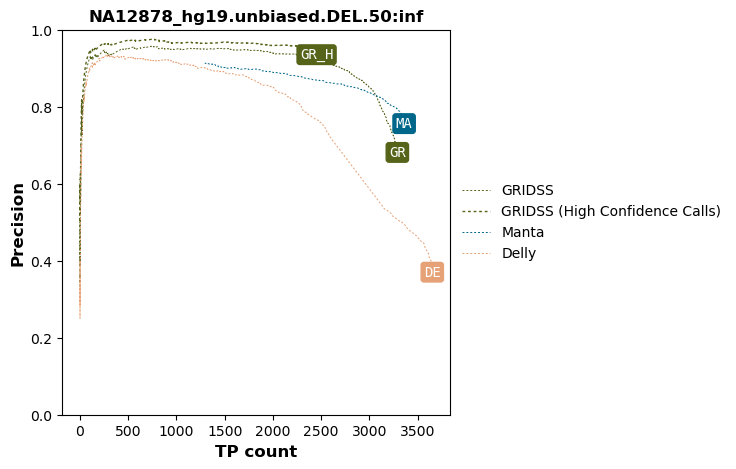

/vast/ai_projects/Papenfuss_SVEnsemble2/svensemble/benchmark.py:592: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='center left', bbox_transform=ax.transAxes, bbox_to_anchor=(1, 0.5), frameon=False)
/tmp/ipykernel_3137141/3870687727.py:76: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='center left', bbox_transform=ax.transAxes, bbox_to_anchor=(1, 0.5), frameon=False)


In [7]:
importlib.reload(benchmark)

view_combs = {
    'NA12878': 'DEL-INS-DUP-INV',
    'HG002': 'DEL-INS',
    'CHM13': 'DEL-INS-INV',
    'HG00514': 'DEL-INS-DUP-INV',
    'NA12878_hg19': 'DEL'
}
model_name = 'unbiased'
svlens = (50, np.inf)
svtypes_list = [
    'DEL', 'INS', 'DUP', 'INV',
    'DEL-INS', 'DEL-INS-INV', 'DEL-INS-DUP-INV'
]
for svtypes in svtypes_list:
    bench_prc(model_name, svtypes, svlens, view_all=False, view_combs=view_combs)

In [ ]:
importlib.reload(benchmark)

model_name = 'unbiased'
svlens = (50, np.inf)
svtypes_list = [
    'DEL', 'INS', 'DUP', 'INV',
    'DEL-INS', 'DEL-INS-INV', 'DEL-INS-DUP-INV'
]
for svtypes in svtypes_list:
    bench_roc(model_name, svtypes, svlens, view=False)

In [ ]:
importlib.reload(benchmark)

model_name = 'unbiased'
svlens = (50, np.inf)
svtypes = 'DEL-INS'

bench_roc(model_name, svtypes, svlens, view=True)